# 08 · Life Sciences: Biology and Medicine

Python is the main language of computational biology and medical data science. This module uses three
mature libraries on realistic problems: **Biopython** for sequences and evolution, **lifelines** for
survival analysis of a real clinical trial, and **scikit-learn** for a diagnostic model.

> These are teaching examples, not medical advice or validated clinical tools.

**You will learn**
1. DNA and protein sequences: transcription, translation, GC content, reading frames
2. Simulating evolution and recovering it with sequence alignment
3. Building a family tree (phylogeny) from sequence distances
4. Survival analysis: Kaplan-Meier curves, the log-rank test and Cox regression on a breast-cancer trial
5. A diagnostic classifier: cross-validation, ROC curves, and choosing a threshold for sensitivity

## 1. Sequences with Biopython
A gene is a DNA sequence; the cell copies it to RNA (*transcription*) and reads RNA three letters at a time
(*codons*) to build a protein (*translation*). We design a gene for a short protein and run it through.

In [1]:
from Bio.Seq import Seq
from Bio.SeqUtils import gc_fraction
from Bio.Data import CodonTable
import random

random.seed(7)
protein = "MALWMRLLPLLALLALWGPDPAAA"      # a signal-peptide-like stretch, 24 amino acids
table = CodonTable.unambiguous_dna_by_id[1]   # the standard genetic code
codons_for = {}
for codon, aa in table.forward_table.items():
    codons_for.setdefault(aa, []).append(codon)

gene = Seq("".join(random.choice(codons_for[aa]) for aa in protein) + "TAA")   # back-translate + stop codon
print("DNA      :", gene)
print("RNA      :", gene.transcribe())
print("protein  :", gene.translate(to_stop=True), "| matches design:", str(gene.translate(to_stop=True)) == protein)
print("GC content:", round(gc_fraction(gene), 3), "| reverse complement:", gene.reverse_complement()[:24], "...")

DNA      : ATGGCCCTCTGGATGAGATTACTTCCTCTATTGGCTTTACTCGCGTTATGGGGTCCGGATCCTGCCGCTGCGTAA
RNA      : AUGGCCCUCUGGAUGAGAUUACUUCCUCUAUUGGCUUUACUCGCGUUAUGGGGUCCGGAUCCUGCCGCUGCGUAA
protein  : MALWMRLLPLLALLALWGPDPAAA | matches design: True
GC content: 0.533 | reverse complement: TTACGCAGCGGCAGGATCCGGACC ...


In [2]:
# the same protein can be written by many DNA sequences: the genetic code is redundant
print({aa: len(c) for aa, c in sorted(codons_for.items())})

# finding open reading frames (ATG ... stop) in a stretch of DNA that hides our gene
noise = lambda n: "".join(random.choice("ACGT") for _ in range(n))
genome = Seq(noise(120) + str(gene) + noise(150))
orfs = []
for frame in range(3):
    prot = str(genome[frame:].translate())
    pos = 0
    for chunk in prot.split("*"):
        start = chunk.find("M")
        if start != -1 and len(chunk) - start >= 20:
            orfs.append((frame, frame + 3 * (pos + start), chunk[start:]))
        pos += len(chunk) + 1
print("ORFs of at least 20 aa:", [(f, s, p) for f, s, p in orfs])

{'A': 4, 'C': 2, 'D': 2, 'E': 2, 'F': 2, 'G': 4, 'H': 2, 'I': 3, 'K': 2, 'L': 6, 'M': 1, 'N': 2, 'P': 4, 'Q': 2, 'R': 6, 'S': 6, 'T': 4, 'V': 4, 'W': 1, 'Y': 2}
ORFs of at least 20 aa: [(0, 120, 'MALWMRLLPLLALLALWGPDPAAA'), (2, 59, 'MHTPLLAVSTPSDWHFYYTQNGPLDEITSSIGFTRVMGSGSCRCVKQNSGNFDRSRRGAPS')]


/home/patito/Developments/academy/python/.venv/lib/python3.12/site-packages/Bio/Seq.py:2874: BiopythonWarning: Partial codon, len(sequence) not a multiple of three. Explicitly trim the sequence or add trailing N before translation. This may become an error in future.
  warnings.warn(


## 2. Simulating evolution, then recovering it by alignment
Starting from an ancestral gene, we let five species diverge: each lineage accumulates point mutations
and a few insertions or deletions. Then we ask Biopython's `PairwiseAligner` to line the sequences back up.

In [3]:
from Bio import Align

def mutate(seq: str, n_subs: int, n_indels: int, rng: random.Random) -> str:
    s = list(seq)
    for _ in range(n_subs):
        i = rng.randrange(len(s)); s[i] = rng.choice([b for b in "ACGT" if b != s[i]])
    for _ in range(n_indels):
        i = rng.randrange(len(s))
        if rng.random() < 0.5: del s[i]
        else: s.insert(i, rng.choice("ACGT"))
    return "".join(s)

rng = random.Random(1)
ancestor = noise(300)
# a tree we choose: ((A,B),(C,(D,E))) with different branch lengths
ab = mutate(ancestor, 18, 1, rng);  cde = mutate(ancestor, 24, 1, rng)
de = mutate(cde, 12, 1, rng)
species = {"A": mutate(ab, 6, 0, rng), "B": mutate(ab, 8, 1, rng), "C": mutate(cde, 10, 1, rng),
           "D": mutate(de, 5, 0, rng), "E": mutate(de, 7, 1, rng)}

aligner = Align.PairwiseAligner(mode="global", match_score=2, mismatch_score=-1,
                                open_gap_score=-4, extend_gap_score=-1)
best = aligner.align(species["A"], species["B"])[0]
print(f"score {best.score:.0f}")
print(str(best)[:300])

score 554
target            0 TTTTGACTACGACTTACTCATTCCCTTGTCGGGGAGTTATGGAACAAGCACGGTGTCTGA
                  0 ||||||||||||||.|||||||||||||||||||||-|||||||||.|||||||||||||
query             0 TTTTGACTACGACTAACTCATTCCCTTGTCGGGGAG-TATGGAACATGCACGGTGTCTGA

target           60 CACTAGAATACAGATAGTGCACACGACCGGCGTCGG


## 3. A family tree from distances
The fraction of differing positions in each aligned pair gives a distance matrix; neighbour joining turns
it into a tree. If the method works, it recovers the grouping we used in the simulation: (A, B) together
and (D, E) together, with C nearer D and E.

A   0.000000
B   0.046667    0.000000
C   0.167785    0.164983    0.000000
D   0.196667    0.193980    0.090000    0.000000
E   0.200669    0.194631    0.096990    0.039867    0.000000
    A   B   C   D   E


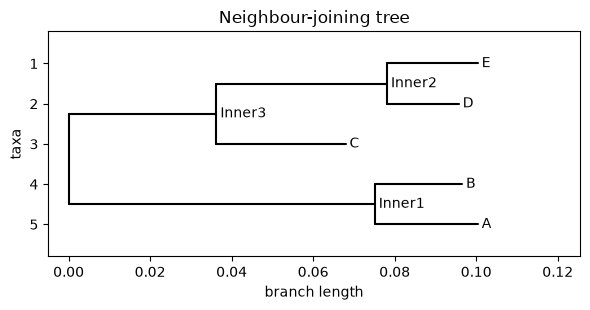

In [4]:
from Bio.Phylo.TreeConstruction import DistanceMatrix, DistanceTreeConstructor
from Bio import Phylo
import matplotlib.pyplot as plt

names = list(species)
def p_distance(a, b):
    aln = aligner.align(a, b)[0]
    s1, s2 = aln[0], aln[1]
    pairs = [(x, y) for x, y in zip(s1, s2) if x != "-" and y != "-"]
    return sum(x != y for x, y in pairs) / len(pairs)

matrix = [[p_distance(species[names[i]], species[names[j]]) for j in range(i)] + [0.0] for i in range(len(names))]
dm = DistanceMatrix(names, matrix)
print(dm)
tree = DistanceTreeConstructor().nj(dm)
tree.root_at_midpoint()
fig, ax = plt.subplots(figsize=(6, 3.2))
Phylo.draw(tree, axes=ax, do_show=False); ax.set_title("Neighbour-joining tree"); plt.tight_layout(); plt.show()

## 4. Survival analysis on a real breast-cancer trial
**GBSG2** (German Breast Cancer Study Group, 686 patients) followed women after surgery and recorded
the time until the cancer came back (`time`, days) or until follow-up ended without recurrence
(`cens = 0`, a *censored* observation). Ignoring censoring biases every average, which is why survival
analysis has its own methods.

The question the trial asked: **does hormonal therapy (`horTh`) lengthen recurrence-free survival?**

In [5]:
from lifelines.datasets import load_gbsg2
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test

gb = load_gbsg2()
print(gb.shape); print(gb["horTh"].value_counts().to_dict(), "| events (recurrence):", int(gb["cens"].sum()))
gb.head()

(686, 10)
{'no': 440, 'yes': 246} | events (recurrence): 299


,horTh,age,menostat,tsize,tgrade,pnodes,progrec,estrec,time,cens
0,no,70,Post,21,II,3,48,66,1814,1
1,yes,56,Post,12,II,7,61,77,2018,1
2,yes,58,Post,35,II,9,52,271,712,1
3,yes,59,Post,17,II,4,60,29,1807,1
4,no,73,Post,35,II,1,26,65,772,1


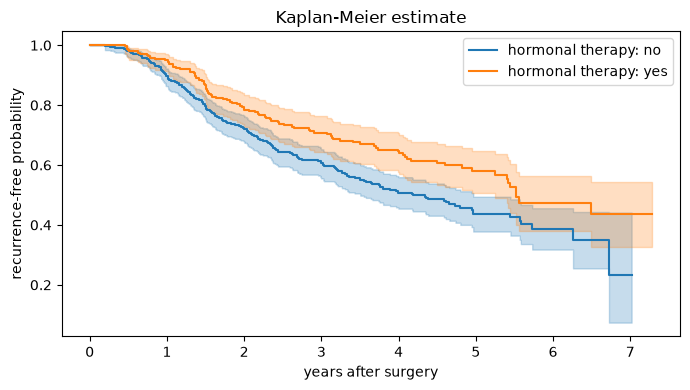

log-rank test p-value: 0.0034


In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for group, d in gb.groupby("horTh"):
    KaplanMeierFitter(label=f"hormonal therapy: {group}").fit(d["time"] / 365.25, d["cens"]).plot_survival_function(ax=ax)
ax.set_xlabel("years after surgery"); ax.set_ylabel("recurrence-free probability"); ax.set_title("Kaplan-Meier estimate")
plt.tight_layout(); plt.show()

yes, no = gb[gb.horTh == "yes"], gb[gb.horTh == "no"]
test = logrank_test(yes["time"], no["time"], event_observed_A=yes["cens"], event_observed_B=no["cens"])
print(f"log-rank test p-value: {test.p_value:.4f}")

The curves separate and the log-rank test says the difference is unlikely to be chance. But treated and
untreated patients may differ in other ways (age, tumour size, lymph nodes). **Cox proportional-hazards
regression** estimates the effect of therapy while adjusting for them; a hazard ratio below 1 means a
lower risk of recurrence.

In [7]:
X = gb.assign(horTh=(gb.horTh == "yes").astype(int), menostat=(gb.menostat == "Post").astype(int),
              tgrade=gb.tgrade.map({"I": 1, "II": 2, "III": 3}))
cph = CoxPHFitter().fit(X[["time", "cens", "horTh", "age", "menostat", "tsize", "tgrade", "pnodes", "progrec", "estrec"]],
                        duration_col="time", event_col="cens")
cph.print_summary(columns=["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"], decimals=3)

<lifelines.CoxPHFitter: fitted with 686 total observations, 387 right-censored observations>
             duration col = 'time'
                event col = 'cens'
      baseline estimation = breslow
   number of observations = 686
number of events observed = 299
   partial log-likelihood = -1737.174
         time fit was run = 2026-10-17 23:25:24 UTC

---
          exp(coef) exp(coef) lower 95% exp(coef) upper 95%       p
covariate                                                          
horTh         0.714               0.554               0.919   0.009
age           0.991               0.973               1.009   0.311
menostat      1.306               0.912               1.871   0.145
tsize         1.008               1.000               1.016   0.051
tgrade        1.324               1.075               1.629   0.008
pnodes        1.051               1.036               1.067 <0.0005
progrec       0.998               0.997               0.999 <0.0005
estrec        1.000               0.999               1.001   0.708
---
Concordance = 0.688
Partial AIC = 3490.349
log-likelihood ratio test = 101.860 on 8 df
-log2(p) of ll-ratio test = 58.965

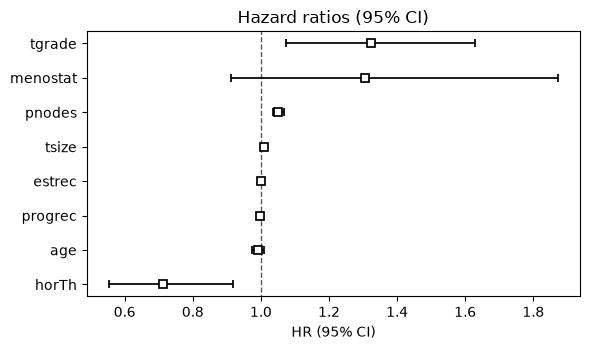

Adjusted for the other factors, hormonal therapy multiplies the risk of recurrence by 0.71 (about 29% lower). More positive lymph nodes and a higher tumour grade raise it.


In [8]:
fig, ax = plt.subplots(figsize=(6, 3.6))
cph.plot(hazard_ratios=True, ax=ax); ax.set_title("Hazard ratios (95% CI)"); plt.tight_layout(); plt.show()
hr = cph.hazard_ratios_["horTh"]
print(f"Adjusted for the other factors, hormonal therapy multiplies the risk of recurrence by {hr:.2f} "
      f"(about {100 * (1 - hr):.0f}% lower). More positive lymph nodes and a higher tumour grade raise it.")

## 5. A diagnostic classifier
The Wisconsin breast-cancer dataset (bundled with scikit-learn) describes cell nuclei from 569 biopsies,
each labelled malignant or benign. In diagnosis the two errors are not equal: missing a malignancy
(false negative) is far worse than a false alarm, so we choose the decision threshold for **sensitivity**,
not accuracy.

cross-validated ROC AUC: 0.996
threshold 0.524: sensitivity 0.958, specificity 0.997, missed malignancies 9, false alarms 1
threshold 0.085: sensitivity 0.995, specificity 0.868, missed malignancies 1, false alarms 47


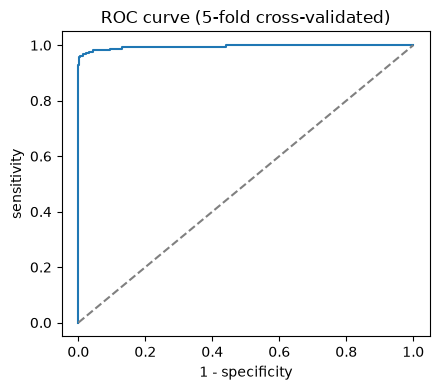

In [9]:
from sklearn.datasets import load_breast_cancer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

data = load_breast_cancer()
y = (data.target == 0).astype(int)                  # 1 = malignant
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, C=0.5))
proba = cross_val_predict(model, data.data, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")[:, 1]
print(f"cross-validated ROC AUC: {roc_auc_score(y, proba):.3f}")

fpr, tpr, thr = roc_curve(y, proba)
for target_sens in (0.95, 0.99):
    i = next(k for k, t in enumerate(tpr) if t >= target_sens)
    tn, fp, fn, tp = confusion_matrix(y, proba >= thr[i]).ravel()
    print(f"threshold {thr[i]:.3f}: sensitivity {tp / (tp + fn):.3f}, specificity {tn / (tn + fp):.3f}, "
          f"missed malignancies {fn}, false alarms {fp}")

plt.figure(figsize=(4.5, 4)); plt.plot(fpr, tpr); plt.plot([0, 1], [0, 1], "--", color="grey")
plt.xlabel("1 - specificity"); plt.ylabel("sensitivity"); plt.title("ROC curve (5-fold cross-validated)"); plt.tight_layout(); plt.show()

## Libraries worth knowing in this field
| Area | Libraries |
|---|---|
| sequences, files, databases | Biopython, scikit-bio, pysam (genomics alignments) |
| single-cell and omics | Scanpy, AnnData |
| protein structure | Biopython PDB, MDAnalysis; AlphaFold predictions are distributed as files these read |
| medical imaging | pydicom, SimpleITK, MONAI (deep learning) |
| survival and clinical statistics | lifelines, scikit-survival, statsmodels |
| epidemiology | epipy, compartment models with SciPy (`solve_ivp`) |

## Exercises
1. Increase the number of mutations in the simulation until neighbour joining gets the tree wrong. How much divergence can it handle?
2. Stratify the Kaplan-Meier curves by tumour grade (`tgrade`) instead of therapy.
3. Replace logistic regression with gradient boosting in the diagnostic model. Does the AUC improve, and is it worth the loss in interpretability?